# Projet de synthèse M201 — MarocShop
Auteur : Ziyad Damghi

# Partie 1 — Découverte, types de variables et nettoyage

In [405]:
import pandas as pd
import numpy as np
import statistics
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

In [406]:
df_org  = pd.read_csv(r"/home/ziyad/Desktop/IA_DATA_2026_2027/02_ISMO_COURS_ET_TP/Principale/Module_1_Math/projet_final/Analyse-des-commandes-et-des-messages-clients-de-MarocShop/data/commandes.csv")

In [407]:
df = df_org.copy()

In [408]:
df.shape

(518, 14)

In [409]:
cat_col = ["ville", "sexe", "categorie", "canal", "entrepot","colis_endommage", "satisfaction", "retour_client"]

for c in cat_col:
    df[c] = df[c].str.strip().str.lower().str.replace('è' , 'e').str.replace('é' , 'e')

In [410]:
for i in cat_col:
    print(df[i].value_counts(), "\n")

ville
casablanca    126
rabat          87
tanger         79
marrakech      74
fes            57
agadir         48
tetouan        47
Name: count, dtype: int64 

sexe
femme    266
homme    242
Name: count, dtype: int64 

categorie
mode            142
electronique    108
maison           99
beaute           92
sport            77
Name: count, dtype: int64 

canal
web            252
application    194
telephone       64
Name: count, dtype: int64 

entrepot
a    255
b    171
c     92
Name: count, dtype: int64 

colis_endommage
non    487
oui     31
Name: count, dtype: int64 

satisfaction
moyen     230
eleve     175
faible     70
Name: count, dtype: int64 

retour_client
non    431
oui     87
Name: count, dtype: int64 



In [411]:
print(df.isna().sum(), "\n")

id_commande               0
date_commande             0
ville                     0
sexe                     10
age_client               23
categorie                 0
canal                     8
nb_articles               6
montant_dh               15
entrepot                  0
delai_livraison_jours    18
colis_endommage           0
satisfaction             43
retour_client             0
dtype: int64 



In [412]:
df.head()

,id_commande,date_commande,ville,sexe,age_client,categorie,canal,nb_articles,montant_dh,entrepot,delai_livraison_jours,colis_endommage,satisfaction,retour_client
0,CMD0001,2025-01-01,casablanca,femme,44.0,beaute,application,3.0,210.97,a,2.0,non,moyen,non
1,CMD0002,2025-01-01,tetouan,femme,26.0,mode,web,5.0,579.45,b,5.0,non,faible,non
2,CMD0003,2025-01-03,tanger,homme,28.0,sport,application,2.0,372.35,b,2.0,non,eleve,non
3,CMD0004,2025-01-05,rabat,femme,18.0,mode,application,3.0,478.11,c,4.0,oui,faible,oui
4,CMD0005,2025-01-05,rabat,femme,41.0,electronique,application,7.0,411.04,c,4.0,non,eleve,non


In [413]:
df.dtypes

id_commande                  str
date_commande                str
ville                        str
sexe                         str
age_client               float64
categorie                    str
canal                        str
nb_articles              float64
montant_dh               float64
entrepot                     str
delai_livraison_jours    float64
colis_endommage              str
satisfaction                 str
retour_client                str
dtype: object

In [414]:
print(f' les nombre des doublans {df.duplicated().sum()}')

 les nombre des doublans 18


In [415]:
valeurs_num = df.select_dtypes(include= "number")
valeurs_cat = df.select_dtypes(include= "str")
for i in valeurs_num :
    manquante_num = ((valeurs_num[i].isnull().mean())*100).round(1)
    print(i ,":" , manquante_num , "%")
for j in valeurs_cat:
    manquante_cat = ((valeurs_cat[j].isnull().mean())*100).round(1)
    
    print(j ,":"  ,manquante_cat , "%")

age_client : 4.4 %
nb_articles : 1.2 %
montant_dh : 2.9 %
delai_livraison_jours : 3.5 %
id_commande : 0.0 %
date_commande : 0.0 %
ville : 0.0 %
sexe : 1.9 %
categorie : 0.0 %
canal : 1.5 %
entrepot : 0.0 %
colis_endommage : 0.0 %
satisfaction : 8.3 %
retour_client : 0.0 %


In [416]:
df.columns.str.strip().str.lower()

Index(['id_commande', 'date_commande', 'ville', 'sexe', 'age_client',
       'categorie', 'canal', 'nb_articles', 'montant_dh', 'entrepot',
       'delai_livraison_jours', 'colis_endommage', 'satisfaction',
       'retour_client'],
      dtype='str')

In [417]:
df['date_commande'] = pd.to_datetime(df['date_commande'] , format= 'mixed')
df['mois'] = df['date_commande'].dt.month


In [418]:
future = df['date_commande'] > pd.Timestamp.today()
future.sum()

np.int64(0)

In [419]:
doublans = df[df.duplicated(keep= False)]
len(doublans)

36

In [420]:
df.duplicated().sum()

np.int64(18)

In [421]:
df = df.drop_duplicates()

In [422]:
df.shape

(500, 15)

In [423]:
df = df.drop_duplicates(subset= 'id_commande')

In [424]:
df.shape

(500, 15)

In [425]:
df.describe()

,date_commande,age_client,nb_articles,montant_dh,delai_livraison_jours,mois
count,500,478.000000,494.000000,485.000000,482.000000,500.000000
mean,2025-07-02 15:07:12,34.941423,2.522267,710.774412,3.537344,6.550000
min,2025-01-01 00:00:00,0.000000,0.000000,-150.000000,-2.000000,1.000000
25%,2025-04-01 18:00:00,27.000000,1.000000,261.170000,2.000000,4.000000
50%,2025-07-04 00:00:00,35.000000,2.000000,385.870000,3.000000,7.000000
75%,2025-09-29 00:00:00,42.000000,3.000000,616.060000,4.000000,9.000000
max,2025-12-30 00:00:00,130.000000,40.000000,32000.000000,60.000000,12.000000
std,NaN,11.686359,2.620428,2227.797358,3.834364,3.422122


In [426]:
df.isnull().sum().sort_values(ascending=False)

satisfaction             40
age_client               22
delai_livraison_jours    18
montant_dh               15
sexe                     10
canal                     8
nb_articles               6
categorie                 0
id_commande               0
date_commande             0
ville                     0
entrepot                  0
colis_endommage           0
retour_client             0
mois                      0
dtype: int64

In [427]:
for c in ["age_client", "nb_articles",  "delai_livraison_jours" , 'montant_dh']:
    df[c] = df[c].fillna(df[c].median())

In [428]:
for c in ["ville", "sexe", "canal", "satisfaction"]:
    df[c] = df[c].fillna(df[c].mode()[0]) 

In [429]:
df.isnull().sum()

id_commande              0
date_commande            0
ville                    0
sexe                     0
age_client               0
categorie                0
canal                    0
nb_articles              0
montant_dh               0
entrepot                 0
delai_livraison_jours    0
colis_endommage          0
satisfaction             0
retour_client            0
mois                     0
dtype: int64

In [430]:
df.to_csv('commandes_nettoye.csv')

# Partie 2 — Mesures centrales
Données utilisées : commandes_nettoye.csv (doublons et manquants traités, outliers conservés)

In [431]:
valeurs_num = df.select_dtypes(include = 'float')
valeurs_cat = df.select_dtypes(include= "str")

In [432]:
for i in valeurs_num:
    MOYENNE = np.mean(valeurs_num[i])
    MEDIANE= np.median(valeurs_num[i])
    MODE= valeurs_num[i].mode()
    print(i, ": moyenne :", MOYENNE, "Median :", MEDIANE, " Mode :", MODE ,'\n') 

age_client : moyenne : 34.944 Median : 35.0  Mode : 0    35.0
Name: age_client, dtype: float64 

nb_articles : moyenne : 2.516 Median : 2.0  Mode : 0    1.0
Name: nb_articles, dtype: float64 

montant_dh : moyenne : 701.02728 Median : 385.87  Mode : 0    385.87
Name: montant_dh, dtype: float64 

delai_livraison_jours : moyenne : 3.518 Median : 3.0  Mode : 0    3.0
Name: delai_livraison_jours, dtype: float64 



In [448]:
for i in ['ville', 'categorie', 'canal' , 'satisfaction'] :
    print(f"le mode de {i} est :{df[i].mode()[0]}")

le mode de ville est :casablanca
le mode de categorie est :mode
le mode de canal est :web
le mode de satisfaction est :moyen


In [449]:
resultat = df.groupby('categorie')['montant_dh'].agg(['mean' , 'median' ])
resultat

,mean,median
categorie,,
beaute,486.666136,193.460
electronique,1119.087549,1041.190
maison,1040.346211,474.430
mode,470.493525,311.700
sport,385.639474,379.575


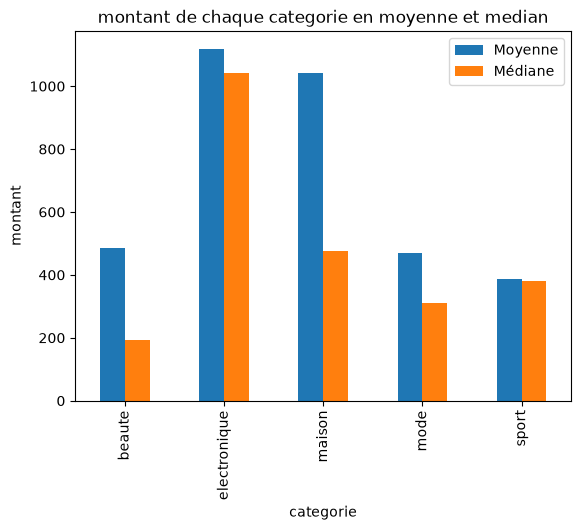

In [435]:
resultat.plot(kind = 'bar')
plt.legend(["Moyenne", "Médiane"])
plt.xlabel('categorie')
plt.ylabel('montant')
plt.title('montant de chaque categorie en moyenne et median')
plt.show()

# Partie 3 — Mesures de dispersion

In [436]:
for i in  ['age_client' , 'montant_dh' , 'delai_livraison_jours']:
    variance = np.var(df[i] ,ddof=1)
    max_i = df[i].max()
    min_i = df[i].min()
    etendu = max_i - min_i
    ecart_type = np.std(df[i] , ddof = 1)
    print(i, ": variance :", variance, "etendu :", etendu, " ecart type :", ecart_type ,'\n')

age_client : variance : 130.5499639278557 etendu : 130.0  ecart type : 11.425846311230329 

montant_dh : variance : 4816968.289223449 etendu : 32150.0  ecart type : 2194.759278195094 

delai_livraison_jours : variance : 14.182040080160322 etendu : 62.0  ecart type : 3.7659049483703546 



In [454]:
df.groupby('ville')['delai_livraison_jours'].agg(['count','std' , 'mean' , 'median', 'max']).sort_values(by = 'std' , ascending= True)

,count,std,mean,median,max
ville,,,,,
marrakech,71,1.141146,3.591549,4.0,7.0
tetouan,46,1.196614,3.652174,4.0,6.0
fes,55,1.212449,3.581818,3.0,6.0
agadir,47,1.268344,5.000000,5.0,7.0
rabat,84,3.963021,3.297619,3.0,38.0
casablanca,121,4.008565,2.487603,2.0,45.0
tanger,76,6.586483,4.289474,3.0,60.0


# Partie 4 — Mesures de position et premiers outliers

In [438]:
Q = [0.25 , 0.50 , 0.75]
D =   [10 , 50 , 90]
C = [95, 99]
resultat_q = []
resultat_d =[] 
resultat_c = []
for i in [Q]:
   q = np.quantile(df['montant_dh'] , i)
   resultat_q.append({'Type' : 'Quantile' , 'niveau' : i , 'valeur' : q})
for i in [D]:
   q = np.percentile(df['montant_dh'] , i)
   resultat_d.append({'Type' : 'Deciles' , 'niveau' : i , 'valeur' : q})
for i in [C]:
   q = np.percentile(df['montant_dh'] , i)
   resultat_c.append({'Type' : 'Centile' , 'niveau' : i , 'valeur' : q})  
print(resultat_q , '\n' , resultat_d , '\n' , resultat_c )


[{'Type': 'Quantile', 'niveau': [0.25, 0.5, 0.75], 'valeur': array([266.0425, 385.87  , 609.7475])}] 
 [{'Type': 'Deciles', 'niveau': [10, 50, 90], 'valeur': array([ 175.601,  385.87 , 1114.86 ])}] 
 [{'Type': 'Centile', 'niveau': [95, 99], 'valeur': array([1490.1595, 2480.5013])}]


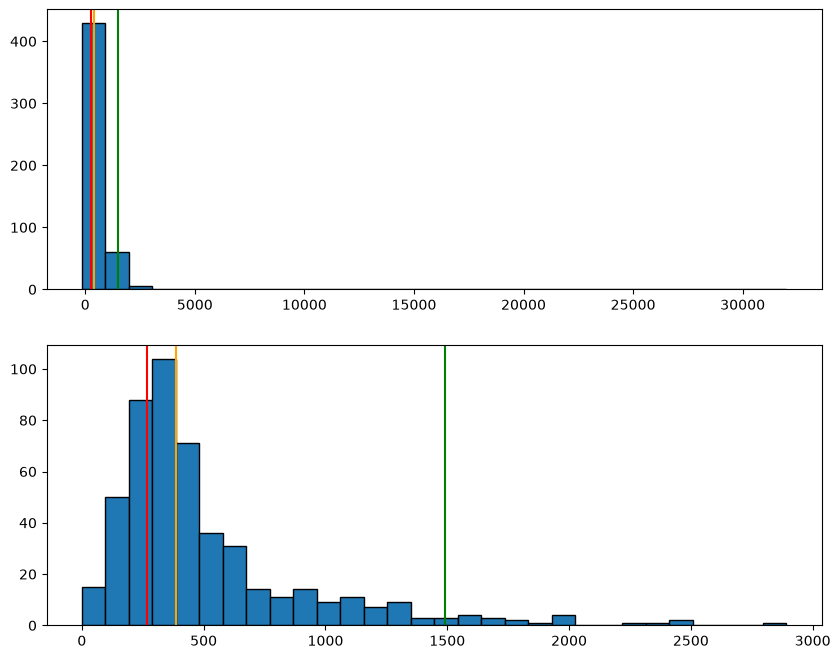

<Figure size 1000x500 with 0 Axes>

In [451]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
q1 = df['montant_dh'].quantile(0.25)
d5 = df['montant_dh'].quantile(0.50)
c95 = df['montant_dh'].quantile(0.95)
plt.figure(figsize=(10, 5))
axes[0].hist(df['montant_dh'], bins=30, edgecolor="black")
axes[0].axvline(q1 , color = 'red')
axes[0].axvline(d5, color = 'orange')
axes[0].axvline(c95 , color = 'green')
axes[1].hist(df['montant_dh'][((df['montant_dh'] >= 0) & (df['montant_dh'] <= 3000))] , bins= 30 , edgecolor = 'black')
axes[1].axvline(q1 , color = 'red')
axes[1].axvline(d5, color = 'orange')
axes[1].axvline(c95 , color = 'green')
plt.show()


In [473]:
moyenne = df['montant_dh'].mean()
ecart = df['montant_dh'].std()
bas = moyenne - 2 * ecart
haut = moyenne + 2 * ecart

masque = (df['montant_dh'] < bas) | (df['montant_dh'] > haut)

print("Nombre détecté :", masque.sum(), '\n')
print(df.loc[masque, ['id_commande', 'montant_dh']])

Nombre détecté : 4 

    id_commande  montant_dh
110     CMD0109     32000.0
211     CMD0207     18500.0
392     CMD0383     25000.0
409     CMD0399     21000.0


In [441]:
df.describe()

,date_commande,age_client,nb_articles,montant_dh,delai_livraison_jours,mois
count,500,500.000000,500.000000,500.000000,500.000000,500.000000
mean,2025-07-02 15:07:12,34.944000,2.516000,701.027280,3.518000,6.550000
min,2025-01-01 00:00:00,0.000000,0.000000,-150.000000,-2.000000,1.000000
25%,2025-04-01 18:00:00,27.000000,1.000000,266.042500,2.000000,4.000000
50%,2025-07-04 00:00:00,35.000000,2.000000,385.870000,3.000000,7.000000
75%,2025-09-29 00:00:00,42.000000,3.000000,609.747500,4.000000,9.000000
max,2025-12-30 00:00:00,130.000000,40.000000,32000.000000,60.000000,12.000000
std,NaN,11.425846,2.605248,2194.759278,3.765905,3.422122


In [442]:
for i in ["age_client", "nb_articles", "montant_dh", "delai_livraison_jours"] :
    q1, q3 = df[i].quantile([0.25, 0.75])
    iqr = q3 - q1
    masque = (df[i] < q1 - 1.5 * iqr) | (df[i] > q3 + 1.5 * iqr)
    print(i, masque.sum(), "outliers")

age_client 3 outliers
nb_articles 8 outliers
montant_dh 47 outliers
delai_livraison_jours 4 outliers


In [443]:
df.describe()

,date_commande,age_client,nb_articles,montant_dh,delai_livraison_jours,mois
count,500,500.000000,500.000000,500.000000,500.000000,500.000000
mean,2025-07-02 15:07:12,34.944000,2.516000,701.027280,3.518000,6.550000
min,2025-01-01 00:00:00,0.000000,0.000000,-150.000000,-2.000000,1.000000
25%,2025-04-01 18:00:00,27.000000,1.000000,266.042500,2.000000,4.000000
50%,2025-07-04 00:00:00,35.000000,2.000000,385.870000,3.000000,7.000000
75%,2025-09-29 00:00:00,42.000000,3.000000,609.747500,4.000000,9.000000
max,2025-12-30 00:00:00,130.000000,40.000000,32000.000000,60.000000,12.000000
std,NaN,11.425846,2.605248,2194.759278,3.765905,3.422122


In [444]:
df.to_csv("commandes_nettoye.csv", index=False)